# 04 · KNN no protocolo de teste final do E7

O [notebook 03](03_modelos_eletrodo_7.ipynb) comparou os modelos no conjunto histórico. O KNN com k=5 e pesos por distância foi escolhido pelo desempenho em validação por campanha (LOCO, 19/30), por bloco (LOBO, 22/30) e por aplicação (LOO, 18/30).

Ajustamos o escalonador e o KNN nas **30 aplicações históricas**. Em seguida, calculamos os atributos e geramos uma previsão por aplicação do protocolo final. Os nomes dos arquivos de teste incluem a linhagem registrada. O código extrai essa informação na etapa de avaliação, depois de calcular as previsões. O pareamento com o PBS usa o número da aplicação nos nomes de arquivo.

In [1]:
from collections import defaultdict
import hashlib
from pathlib import Path
import re
import sys
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.path import Path as MarkerPath
from matplotlib.transforms import Affine2D
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

RAIZ = Path.cwd()
PACOTE = RAIZ / 'TCC_EIS_Modelos_Basicos'
PASTA_TESTE = RAIZ / 'Protocolo_teste_final'
assert (PACOTE / 'dados').is_dir() and PASTA_TESTE.is_dir(), 'Abra o notebook na pasta raiz.'
sys.path.insert(0, str(PACOTE))
from eis_utils import FREQUENCY, PHASE, band_average, read_all
from modelos_basicos import basic_models

PASTA_FIGURAS = RAIZ / 'imagens_prontas'
PASTA_FIGURAS.mkdir(exist_ok=True)
ARQUIVO_HISTORICO = PACOTE / 'dados' / 'Medicoes_EIS_Por_Dispositivo_ATUALIZADO_E02.zip'
ORDEM = ['MCF10A', 'HCC1806']
BORDAS = [.1, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
ATRIBUTOS = [f'F_b{i}' for i in range(1, len(BORDAS))]
HISTORICO = pd.read_csv(
    PACOTE / 'dados' / 'E7_30_aplicacoes_historicas_caracteristicas.csv',
    usecols=['id', 'campanha', 'classe', *ATRIBUTOS],
)
x_treino = HISTORICO[ATRIBUTOS].to_numpy(float)
y_treino = HISTORICO.classe.to_numpy()
assert x_treino.shape == (30, 7) and np.isfinite(x_treino).all() and HISTORICO.id.is_unique
assert HISTORICO.classe.value_counts().to_dict() == dict.fromkeys(ORDEM, 15)

knn = basic_models()['KNN (k=5)']
y_treino_binario = HISTORICO.classe.eq('HCC1806').to_numpy(dtype=int)
knn.fit(x_treino, y_treino_binario)
print(f'Treino: {len(y_treino)} aplicações | scikit-learn {sklearn.__version__}')
print(knn)

Treino: 30 aplicações | scikit-learn 1.9.1
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(weights='distance'))])


## Atributos espectrais e pareamento

Para cada frequência, calculamos a média das três leituras da coluna -Phase (°) para a amostra e para o PBS. Subtraímos a média do PBS da média da amostra e agrupamos as diferenças em sete bandas de 0,1 Hz a 1 MHz.

Conferimos a fórmula reproduzindo as 210 características da tabela histórica a partir dos espectros brutos. No teste, o pareamento segue os números 01 a 16. Os arquivos T04, T06 e T07 pertencem ao protocolo final e foram associados a P04, P06 e P07, respectivamente. A divisão entre histórico e teste também foi conferida pelo conteúdo dos arquivos.

In [2]:
def fase_por_banda(freq, fase_ves, fase_pbs):
    delta = fase_ves - fase_pbs
    return [band_average(freq, delta, lo, hi) for lo, hi in zip(BORDAS, BORDAS[1:])]


etapas = {
    'OLD': '01_Campanha_inicial', 'T': '03_T01-T08',
    'V2': '04_Treinamento_V2', 'V3': '05_Validacao_V3',
}
espectros = read_all(ARQUIVO_HISTORICO).query("electrode == 'E07'")
recalculado = []
for r in HISTORICO.itertuples(index=False):
    id_gota = r.id.rsplit('_', 1)[-1]
    etapa = espectros[espectros.folder.str.endswith(etapas[r.campanha])]
    ves, = etapa[etapa.filename.str.contains(rf'(?:^|_){id_gota}_')].itertuples()
    pbs, = etapa[etapa.filename.str.contains(rf'(?:^|_)P{id_gota[1:]}_')].itertuples()
    assert ves.n_scans == pbs.n_scans == 3 and np.array_equal(ves.f, pbs.f)
    recalculado.append(fase_por_banda(ves.f, ves.p.mean(axis=0), pbs.p.mean(axis=0)))
np.testing.assert_allclose(recalculado, x_treino, atol=1e-10, rtol=0)

arquivos_teste = sorted(PASTA_TESTE.glob('*.txt'))
with zipfile.ZipFile(ARQUIVO_HISTORICO) as arquivo:
    hashes_historicos = {
        hashlib.sha256(arquivo.read(nome)).digest()
        for nome in arquivo.namelist() if nome.startswith('E07/') and nome.endswith('.txt')
    }
assert len(arquivos_teste) == 96 and hashes_historicos
assert all(hashlib.sha256(arq.read_bytes()).digest() not in hashes_historicos for arq in arquivos_teste)

grupos = defaultdict(dict)
for arq in arquivos_teste:
    partes = re.fullmatch(r'(P|TF?)(\d{2})_[^()]+(?:\(([12])\))?\.txt', arq.name)
    assert partes is not None, arq.name
    prefixo, numero, leitura = partes.groups()
    chave = ('PBS' if prefixo == 'P' else 'VEs', int(numero))
    leitura = int(leitura or '0')
    assert leitura not in grupos[chave], arq.name
    grupos[chave][leitura] = arq
numeros = list(range(1, 17))
assert set(grupos) == {(material, n) for material in ['VEs', 'PBS'] for n in numeros}


def ler_triplicata(arquivos):
    assert set(arquivos) == {0, 1, 2}, arquivos
    tabelas = [
        pd.read_csv(arquivos[i], usecols=[FREQUENCY, PHASE], encoding='utf-8-sig')
        .sort_values(FREQUENCY) for i in [0, 1, 2]
    ]
    freq = tabelas[0][FREQUENCY].to_numpy(float)
    fases = np.stack([t[PHASE].to_numpy(float) for t in tabelas])
    assert len(freq) == 71 and np.all(np.diff(freq) > 0) and np.isfinite(fases).all()
    assert all(np.array_equal(freq, t[FREQUENCY].to_numpy(float)) for t in tabelas)
    return freq, fases.mean(axis=0)


atributos_teste = []
for n in numeros:
    freq, fase_ves = ler_triplicata(grupos['VEs', n])
    freq_pbs, fase_pbs = ler_triplicata(grupos['PBS', n])
    assert np.array_equal(freq, freq_pbs)
    atributos_teste.append(fase_por_banda(freq, fase_ves, fase_pbs))
x_teste = np.asarray(atributos_teste)
assert x_teste.shape == (16, 7) and np.isfinite(x_teste).all()
previsto = np.asarray(ORDEM)[knn.predict(x_teste)]
indice_hcc = np.flatnonzero(knn.classes_ == 1).item()
voto_hcc = knn.predict_proba(x_teste)[:, indice_hcc]
print('Previsões geradas para as 16 aplicações.')

Previsões geradas para as 16 aplicações.


## Avaliação por aplicação

A linhagem registrada de cada gota é extraída do nome do arquivo. Os três arquivos de cada gota devem indicar a mesma linhagem. O peso de voto em HCC1806 na tabela vem dos vizinhos ponderados por distância.

In [3]:
identidades = {'MCF': 'MCF10A', 'HCC': 'HCC1806'}
registrado = []
for n in numeros:
    tokens = {arq.stem.split('_')[1] for arq in grupos['VEs', n].values()}
    token, = tokens
    registrado.append(identidades[token])
resultado = pd.DataFrame({
    'aplicacao': [f'{n:02d}' for n in numeros],
    'arquivo_ves': [grupos['VEs', n][0].name for n in numeros],
    'arquivo_pbs': [grupos['PBS', n][0].name for n in numeros],
    'registrada': registrado,
    'prevista': previsto,
    'voto_hcc_pct': 100 * voto_hcc,
})
resultado['acerto'] = resultado.registrada.eq(resultado.prevista)
matriz = confusion_matrix(registrado, previsto, labels=ORDEM)
acertos = int(resultado.acerto.sum())
assert acertos == np.trace(matriz) and matriz.sum() == len(numeros)
print(f'{acertos}/{len(numeros)} acertos ({acertos / len(numeros):.2%})')
print(f'Acurácia balanceada: {balanced_accuracy_score(registrado, previsto):.2%}')
display(resultado.round({'voto_hcc_pct': 2}))
resultado.to_csv(RAIZ / 'previsoes_knn_teste_final.csv', index=False, float_format='%.8f')

9/16 acertos (56.25%)
Acurácia balanceada: 56.25%


,aplicacao,arquivo_ves,arquivo_pbs,registrada,prevista,voto_hcc_pct,acerto
0,01,TF01_HCC_eletrodo7.txt,P01_eletrodo7.txt,HCC1806,MCF10A,27.54,False
1,02,TF02_MCF_eletrodo7.txt,P02_eletrodo7.txt,MCF10A,MCF10A,17.58,True
2,03,TF03_HCC_eletrodo7.txt,P03_eletrodo7.txt,HCC1806,HCC1806,59.23,True
3,04,T04_MCF_eletrodo7.txt,P04_eletrodo7.txt,MCF10A,HCC1806,100.00,False
4,05,TF05_MCF_eletrodo7.txt,P05_eletrodo7.txt,MCF10A,HCC1806,82.05,False
5,06,T06_HCC_eletrodo7.txt,P06_eletrodo7.txt,HCC1806,HCC1806,56.04,True
6,07,T07_HCC_eletrodo7.txt,P07_eletrodo7.txt,HCC1806,MCF10A,38.86,False
7,08,TF08_MCF_eletrodo7.txt,P08_eletrodo7.txt,MCF10A,HCC1806,64.43,False
8,09,TF09_MCF_eletrodo7.txt,P09_eletrodo7.txt,MCF10A,HCC1806,66.20,False
9,10,TF10_HCC_eletrodo7.txt,P10_eletrodo7.txt,HCC1806,HCC1806,100.00,True


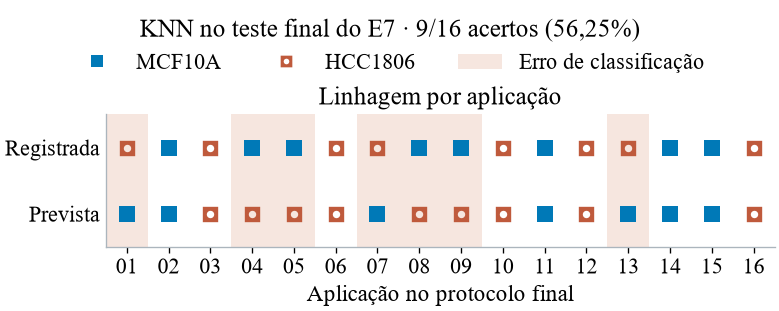

In [4]:
plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42, 'figure.dpi': 120,
    'font.size': 11, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'legend.fontsize': 11, 'legend.title_fontsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#ABB5BD',
    'figure.constrained_layout.use': True,
})
azul, terracota, texto = '#0079B7', '#BF5A3C', '#202934'
quadrado_vazado = MarkerPath.make_compound_path(
    MarkerPath.unit_rectangle().transformed(Affine2D().translate(-.5, -.5)),
    MarkerPath.unit_circle().transformed(Affine2D().scale(.24, -.24)),
)
estilos = {'MCF10A': (azul, 's'), 'HCC1806': (terracota, quadrado_vazado)}
fundo_erro = '#F6E6DF'
with plt.rc_context({'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'axes.labelsize': 14, 'axes.titlesize': 15, 'figure.labelsize': 14,
                     'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    fig, ax = plt.subplots(figsize=(16.5 / 2.54, 6.6 / 2.54))
    x = np.arange(len(resultado))
    for i in x[~resultado.acerto.to_numpy()]:
        ax.axvspan(i - .5, i + .5, facecolor=fundo_erro, edgecolor='none', zorder=0)
    for linha, coluna in [(1, 'registrada'), (0, 'prevista')]:
        for linhagem, (cor, marcador) in estilos.items():
            indices = x[resultado[coluna].eq(linhagem)]
            ax.scatter(indices, np.full(len(indices), linha), color=cor, marker=marcador,
                       s=85, linewidths=0)
    ax.set_xticks(x, resultado.aplicacao)
    ax.set_yticks([0, 1], ['Prevista', 'Registrada'])
    ax.set(xlim=(-.5, len(x) - .5), ylim=(-.5, 1.5), title='Linhagem por aplicação',
           xlabel='Aplicação no protocolo final')
    ax.tick_params(axis='y', length=0)

    legenda = [
        Line2D([], [], marker=m, ls='', color=c, markeredgewidth=0, markersize=7, label=l)
        for l, (c, m) in estilos.items()
    ] + [Patch(facecolor=fundo_erro, edgecolor='none', label='Erro de classificação')]
    percentual = f'{100 * acertos / len(resultado):.2f}'.replace('.', ',')
    fig.legend(handles=legenda, loc='outside upper center', ncol=3, frameon=False,
               title=f'KNN no teste final do E7 · {acertos}/{len(resultado)} acertos ({percentual}%)')
    fig.savefig(PASTA_FIGURAS / 'knn_protocolo_teste_final.pdf')
    plt.show()



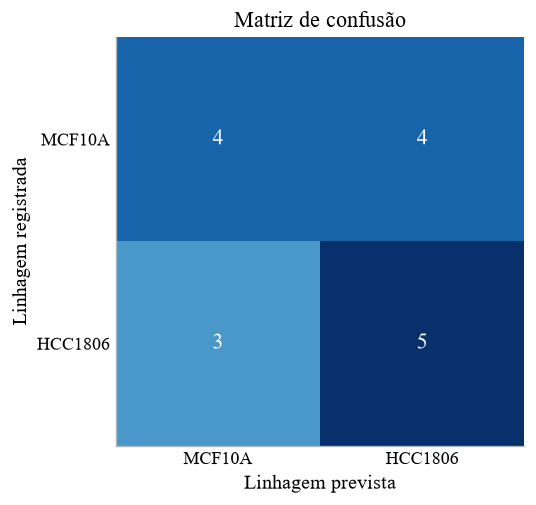

In [5]:
fig_matriz, ax_matriz = plt.subplots(figsize=(4.4, 4.1))
ax_matriz.imshow(matriz, cmap='Blues', vmin=0, vmax=matriz.max())
for (i, j), valor in np.ndenumerate(matriz):
    ax_matriz.text(j, i, f'{valor}', ha='center', va='center', fontsize=13,
                   color='white' if valor > .58 * matriz.max() else texto)
ax_matriz.set_xticks([0, 1], ORDEM)
ax_matriz.set_yticks([0, 1], ORDEM)
ax_matriz.tick_params(length=0)
ax_matriz.set(title='Matriz de confusão', xlabel='Linhagem prevista', ylabel='Linhagem registrada')
fig_matriz.savefig(PASTA_FIGURAS / 'knn_teste_final_matriz_confusao.pdf', bbox_inches='tight')
plt.show()

## Margem de voto por aplicação

Calculamos a diferença entre o peso de voto para a linhagem registrada e o peso para a outra linhagem, em pontos percentuais. Uma margem positiva indica acerto, uma negativa indica erro e zero indica empate. Quanto mais longe de zero, maior a diferença entre os votos ponderados dos vizinhos.

Por exemplo, a aplicação 04 era MCF10A e recebeu todo o peso de voto em HCC1806, resultando em −100 pontos percentuais.

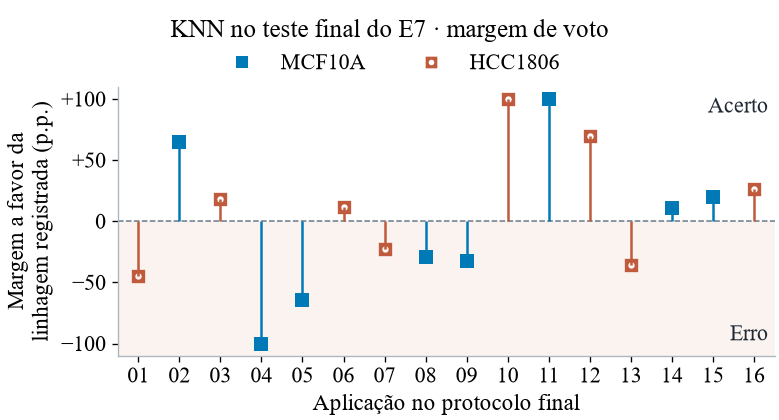

In [6]:
voto_registrada = np.where(resultado.registrada.eq('HCC1806'),
                           resultado.voto_hcc_pct, 100 - resultado.voto_hcc_pct)
margem = 2 * voto_registrada - 100
sem_empate = margem != 0
assert np.array_equal(margem[sem_empate] > 0, resultado.acerto.to_numpy()[sem_empate])

with plt.rc_context({'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'axes.labelsize': 14, 'axes.titlesize': 15, 'figure.labelsize': 14,
                     'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    fig_margem, ax_margem = plt.subplots(figsize=(16.5 / 2.54, 8.9 / 2.54))
    ax_margem.axhspan(-110, 0, facecolor=fundo_erro, alpha=.45, zorder=0)
    ax_margem.axhline(0, color='#667785', lw=.9, ls='--', zorder=2)
    for linhagem, (cor, marcador) in estilos.items():
        indices = x[resultado.registrada.eq(linhagem)]
        ax_margem.vlines(indices, 0, margem[indices], color=cor, lw=1.5)
        ax_margem.scatter(indices, margem[indices], color=cor, marker=marcador,
                          s=64, linewidths=0, zorder=3)
    rotulos = [-100, -50, 0, 50, 100]
    ax_margem.set_yticks(rotulos, ['−100', '−50', '0', '+50', '+100'])
    ax_margem.set_xticks(x, resultado.aplicacao)
    ax_margem.set(xlim=(-.5, len(x) - .5), ylim=(-110, 110),
                  xlabel='Aplicação no protocolo final',
                  ylabel='Margem a favor da\nlinhagem registrada (p.p.)')
    ax_margem.text(.99, .96, 'Acerto', transform=ax_margem.transAxes, ha='right', va='top', color=texto)
    ax_margem.text(.99, .04, 'Erro', transform=ax_margem.transAxes, ha='right', va='bottom', color=texto)
    fig_margem.legend(handles=legenda[:2], loc='outside upper center', ncol=2, frameon=False,
                      title='KNN no teste final do E7 · margem de voto')
    fig_margem.savefig(PASTA_FIGURAS / 'knn_teste_final_margem_decisao.pdf')
    plt.show()

O KNN acertou 9 das 16 aplicações (56,25%). Foram 4/8 acertos em MCF10A e 5/8 em HCC1806. Na matriz de confusão, a diagonal mostra os acertos. A tabela registra o pareamento com o PBS e a previsão de cada aplicação.